In [1]:
import pandas as pd
import numpy as np
import re
import html
import time
import joblib
import warnings
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
def remove_html(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = html.unescape(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
def lowercase(text):
    return text.lower()
def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)
def remove_stopwords(text):
    words = text.split()
    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS]
    return " ".join(filtered_words)
import nltk
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
try:
    nltk.data.find("corpora/wordnet")
except LookupError:
    nltk.download("wordnet")
try:
    nltk.data.find("corpora/omw-1.4")
except LookupError:
    nltk.download("omw-1.4")
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
def stem_text(text):
    return " ".join(
        stemmer.stem(word) for word in text.split())
def lemmatize_text(text):
    return " ".join(
        lemmatizer.lemmatize(word) for word in text.split())
def preprocess_E1(text):
    return remove_html(text)
def preprocess_E2(text):
    return lowercase(remove_html(text))
def preprocess_E3(text):
    return remove_punctuation(lowercase(remove_html(text)))
def preprocess_E4(text):
    return remove_stopwords(remove_punctuation(lowercase(remove_html(text))))
def preprocess_E5(text):
    return stem_text(preprocess_E4(text))
def preprocess_E6(text):
    return lemmatize_text(preprocess_E4(text))
print("Preprocessing functions defined successfully!")

Preprocessing functions defined successfully!


[nltk_data] Downloading package wordnet to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [3]:
PROJECT_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "processed" / "train.csv"
    if candidate.exists():
        PROJECT_ROOT = folder
        DATA_PATH = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/processed/train.csv.")
train_df = pd.read_csv(DATA_PATH)
MODEL_PATH = (PROJECT_ROOT / "results" / "models" / "best_tuned_model.pkl")
if not MODEL_PATH.exists():
    raise FileNotFoundError("Best tuned model not found.")
best_tuned_model = joblib.load(MODEL_PATH)
print("Project root:", PROJECT_ROOT)
print("Training dataset shape:", train_df.shape)
print("Saved tuned model loaded successfully!")
print("\nModel pipeline:")
print(best_tuned_model)
classifier = best_tuned_model.named_steps["classifier"]
vectorizer = best_tuned_model.named_steps["vectorizer"]
print("Classifier:", type(classifier).__name__)
print("Vectorizer:", type(vectorizer).__name__)
print("\nClassifier parameters:")
print(classifier.get_params())
print("\nVectorizer parameters:")
print(vectorizer.get_params())

Project root: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment
Training dataset shape: (40000, 3)
Saved tuned model loaded successfully!

Model pipeline:
Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(lowercase=False,
                                 preprocessor=<function preprocess_E2 at 0x000001B0B0145D20>)),
                ('classifier',
                 LogisticRegression(C=10, max_iter=1000, random_state=42,
                                    solver='liblinear'))])
Classifier: LogisticRegression
Vectorizer: TfidfVectorizer

Classifier parameters:
{'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Vectorizer parameters:
{'analyzer': 'word', 'binary': False, 'decode_error': 'strict', 'dtype': <class 'numpy.float64'>, 'encoding': 'u

In [17]:
# Create a pool containing ONLY the 32,000 training reviews
subset_pool = pd.DataFrame({
    "review": X_train,
    "sentiment": y_train
})

training_sizes = [
    1000,
    5000,
    10000,
    20000,
    30000,
    32000
]

learning_curve_results = []

for size in training_sizes:

    print("\nTraining with", size, "reviews...")

    samples_per_class = size // 2

    positive_samples = subset_pool[
        subset_pool["sentiment"] == "positive"
    ].sample(
        n=samples_per_class,
        random_state=42 + size
    )

    negative_samples = subset_pool[
        subset_pool["sentiment"] == "negative"
    ].sample(
        n=samples_per_class, random_state=42 + size)
    subset = pd.concat([positive_samples, negative_samples]).sample(frac=1, random_state=42)
    X_subset = subset["review"]
    y_subset = subset["sentiment"]
    model = clone(best_tuned_model)
    start_time = time.time()
    model.fit(X_subset, y_subset)
    training_time = time.time() - start_time
    train_predictions = model.predict(X_subset)
    val_predictions = model.predict(X_val)
    train_f1 = f1_score(y_subset, train_predictions, pos_label="positive")
    val_f1 = f1_score(y_val, val_predictions, pos_label="positive")
    learning_curve_results.append({"Training Samples": size, "Training F1-Score": train_f1, "Validation F1-Score": val_f1, "Training Time (seconds)": training_time})
    print("Training F1:", round(train_f1, 4))
    print("Validation F1:", round(val_f1, 4))
    print("Time:", round(training_time, 2), "seconds")
learning_curve_df = pd.DataFrame(learning_curve_results)
print("\nCORRECTED LEARNING CURVE RESULTS")
display(learning_curve_df.round(4))


Training with 1000 reviews...
Training F1: 1.0
Validation F1: 0.8246
Time: 0.26 seconds

Training with 5000 reviews...
Training F1: 0.9988
Validation F1: 0.8673
Time: 1.73 seconds

Training with 10000 reviews...
Training F1: 0.9948
Validation F1: 0.8779
Time: 4.36 seconds

Training with 20000 reviews...
Training F1: 0.9889
Validation F1: 0.892
Time: 9.04 seconds

Training with 30000 reviews...
Training F1: 0.9851
Validation F1: 0.899
Time: 13.25 seconds

Training with 32000 reviews...
Training F1: 0.9847
Validation F1: 0.9016
Time: 13.05 seconds

CORRECTED LEARNING CURVE RESULTS


,Training Samples,Training F1-Score,Validation F1-Score,Training Time (seconds)
0,1000,1.0000,0.8246,0.2641
1,5000,0.9988,0.8673,1.7277
2,10000,0.9948,0.8779,4.3646
3,20000,0.9889,0.8920,9.0374
4,30000,0.9851,0.8990,13.2498
5,32000,0.9847,0.9016,13.0548


In [5]:
training_sizes = [ 1000, 5000, 10000, 20000, 30000, 32000]
learning_curve_results = []
for size in training_sizes:
    print("\nTraining with", size, "reviews...")
    samples_per_class = size // 2
    positive_samples = train_df[ train_df["sentiment"] == "positive"].sample(n=samples_per_class, random_state=42 + size)
    negative_samples = train_df[ train_df["sentiment"] == "negative"].sample(n=samples_per_class, random_state=42 + size)
    subset = pd.concat([positive_samples, negative_samples]).sample(frac=1, random_state=42)
    X_subset = subset["review"]
    y_subset = subset["sentiment"]
    model = clone(best_tuned_model)
    start_time = time.time()
    model.fit(X_subset, y_subset)
    training_time = time.time() - start_time
    train_predictions = model.predict(X_subset)
    val_predictions = model.predict(X_val)
    train_f1 = f1_score(y_subset, train_predictions, pos_label="positive")
    val_f1 = f1_score( y_val, val_predictions, pos_label="positive")
    learning_curve_results.append({
        "Training Samples": size,
        "Training F1-Score": train_f1,
        "Validation F1-Score": val_f1,
        "Training Time (seconds)": training_time})
    print("Training F1:", round(train_f1, 4))
    print("Validation F1:", round(val_f1, 4))
    print("Time:", round(training_time, 2), "seconds")
learning_curve_df = pd.DataFrame(learning_curve_results)
print("\nLEARNING CURVE RESULTS")
display(learning_curve_df.round(4))


Training with 1000 reviews...
Training F1: 1.0
Validation F1: 0.8429
Time: 0.43 seconds

Training with 5000 reviews...
Training F1: 0.9972
Validation F1: 0.8803
Time: 1.5 seconds

Training with 10000 reviews...
Training F1: 0.9949
Validation F1: 0.907
Time: 3.76 seconds

Training with 20000 reviews...
Training F1: 0.9892
Validation F1: 0.9423
Time: 6.97 seconds

Training with 30000 reviews...
Training F1: 0.9868
Validation F1: 0.9643
Time: 10.47 seconds

Training with 32000 reviews...
Training F1: 0.9853
Validation F1: 0.9684
Time: 9.94 seconds

LEARNING CURVE RESULTS


,Training Samples,Training F1-Score,Validation F1-Score,Training Time (seconds)
0,1000,1.0000,0.8429,0.4262
1,5000,0.9972,0.8803,1.5039
2,10000,0.9949,0.9070,3.7579
3,20000,0.9892,0.9423,6.9702
4,30000,0.9868,0.9643,10.4657
5,32000,0.9853,0.9684,9.9426


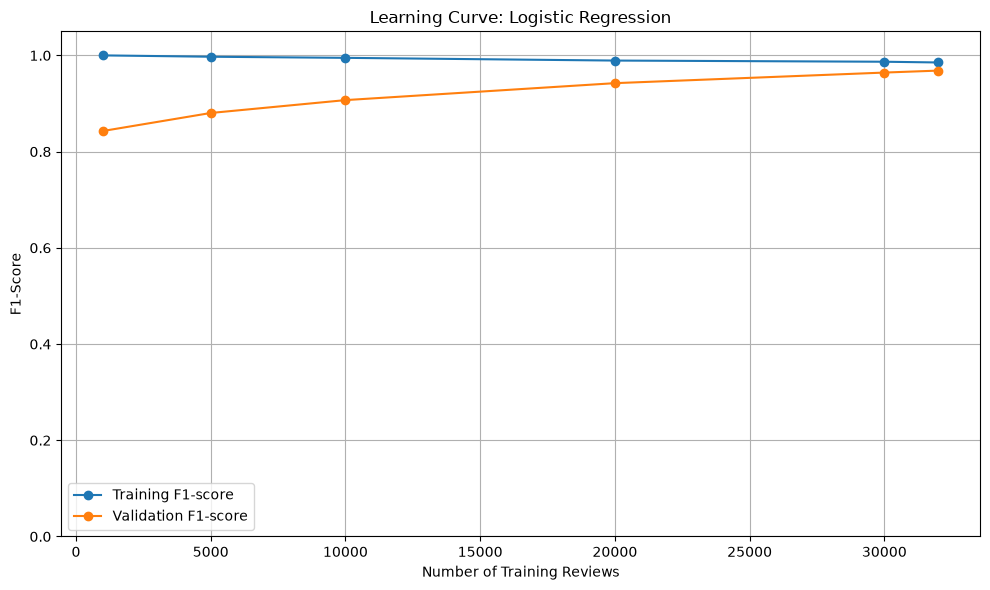

In [6]:
plt.figure(figsize=(10, 6))
plt.plot( learning_curve_df["Training Samples"], learning_curve_df["Training F1-Score"], marker="o", label="Training F1-score")
plt.plot(learning_curve_df["Training Samples"], learning_curve_df["Validation F1-Score"], marker="o", label="Validation F1-score")
plt.title("Learning Curve: Logistic Regression")
plt.xlabel("Number of Training Reviews")
plt.ylabel("F1-Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
final_model = clone(best_tuned_model)
start_time = time.time()
final_model.fit(X, y)
final_training_time = time.time() - start_time
print("Final model trained successfully!")
print("Training samples:", len(X))
print("Training time:", round(final_training_time, 2), "seconds")
print("Final classifier:", type(final_model.named_steps["classifier"]).__name__)

Final model trained successfully!
Training samples: 40000
Training time: 12.17 seconds
Final classifier: LogisticRegression


In [8]:
TEST_PATH = (PROJECT_ROOT / "data" / "processed" / "test.csv")
if not TEST_PATH.exists():
    raise FileNotFoundError("Could not locate data/processed/test.csv.")
test_df = pd.read_csv(TEST_PATH)
X_test = test_df["review"]
y_test = test_df["sentiment"]
print("Test dataset loaded successfully!")
print("Test samples:", len(test_df))
print("\nTest sentiment distribution:")
print(y_test.value_counts())

Test dataset loaded successfully!
Test samples: 10000

Test sentiment distribution:
sentiment
positive    5000
negative    5000
Name: count, dtype: int64


In [9]:
test_predictions = final_model.predict(X_test)
classifier = final_model.named_steps["classifier"]
if hasattr(classifier, "predict_proba"):
    positive_index = list(classifier.classes_).index("positive")
    test_scores = final_model.predict_proba(X_test)[:, positive_index]
else:
    test_scores = final_model.decision_function(X_test)
final_accuracy = accuracy_score(y_test, test_predictions)
final_precision = precision_score(y_test, test_predictions, pos_label="positive")
final_recall = recall_score(y_test, test_predictions, pos_label="positive")
final_f1 = f1_score(y_test, test_predictions, pos_label="positive")
final_roc_auc = roc_auc_score(
    (y_test == "positive").astype(int),
    test_scores)
final_metrics = pd.DataFrame([{
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-Score": final_f1,
    "ROC-AUC": final_roc_auc}])
print("FINAL TEST RESULTS")
print("=" * 50)
display(final_metrics.round(4))

FINAL TEST RESULTS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,0.8958,0.8879,0.906,0.8969,0.9632


FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89      5000
    Positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



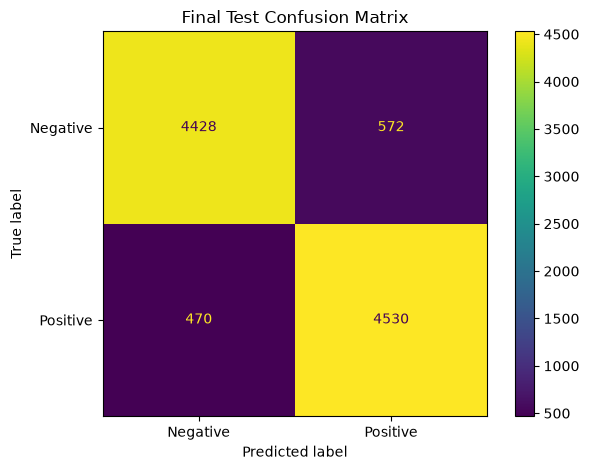

In [10]:
print("FINAL CLASSIFICATION REPORT")
print("=" * 60)
print(
    classification_report(y_test, test_predictions, target_names=["Negative", "Positive"]))
cm = confusion_matrix(y_test, test_predictions, labels=["negative", "positive"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot()
plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
classifier = final_model.named_steps["classifier"]
vectorizer = final_model.named_steps["vectorizer"]
if not isinstance(classifier, LogisticRegression):
    raise TypeError("This interpretation cell expects Logistic Regression.")
feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))
assert len(feature_names) == len(coefficients), ("Feature names and coefficients do not match!")
word_importance = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients})
top_positive_words = word_importance.sort_values(by="Coefficient", ascending=False).head(20)
top_negative_words = word_importance.sort_values(by="Coefficient", ascending=True).head(20)
print("\nTOP 20 POSITIVE WORDS")
display(top_positive_words.reset_index(drop=True).round(4))
print("\nTOP 20 NEGATIVE WORDS")
display(top_negative_words.reset_index(drop=True).round(4))

Number of features: 92544
Number of coefficients: 92544

TOP 20 POSITIVE WORDS


,Word,Coefficient
0,excellent,12.9052
1,great,12.1443
2,perfect,9.3485
3,today,9.0335
4,superb,8.7624
5,brilliant,8.6624
6,wonderful,8.5598
7,amazing,8.2832
8,highly,8.2349
9,refreshing,8.1532



TOP 20 NEGATIVE WORDS


,Word,Coefficient
0,worst,-19.5865
1,waste,-15.2361
2,awful,-14.8104
3,boring,-13.0275
4,bad,-11.3244
5,poor,-11.1586
6,terrible,-11.0089
7,disappointing,-10.6421
8,horrible,-10.2909
9,disappointment,-10.2154


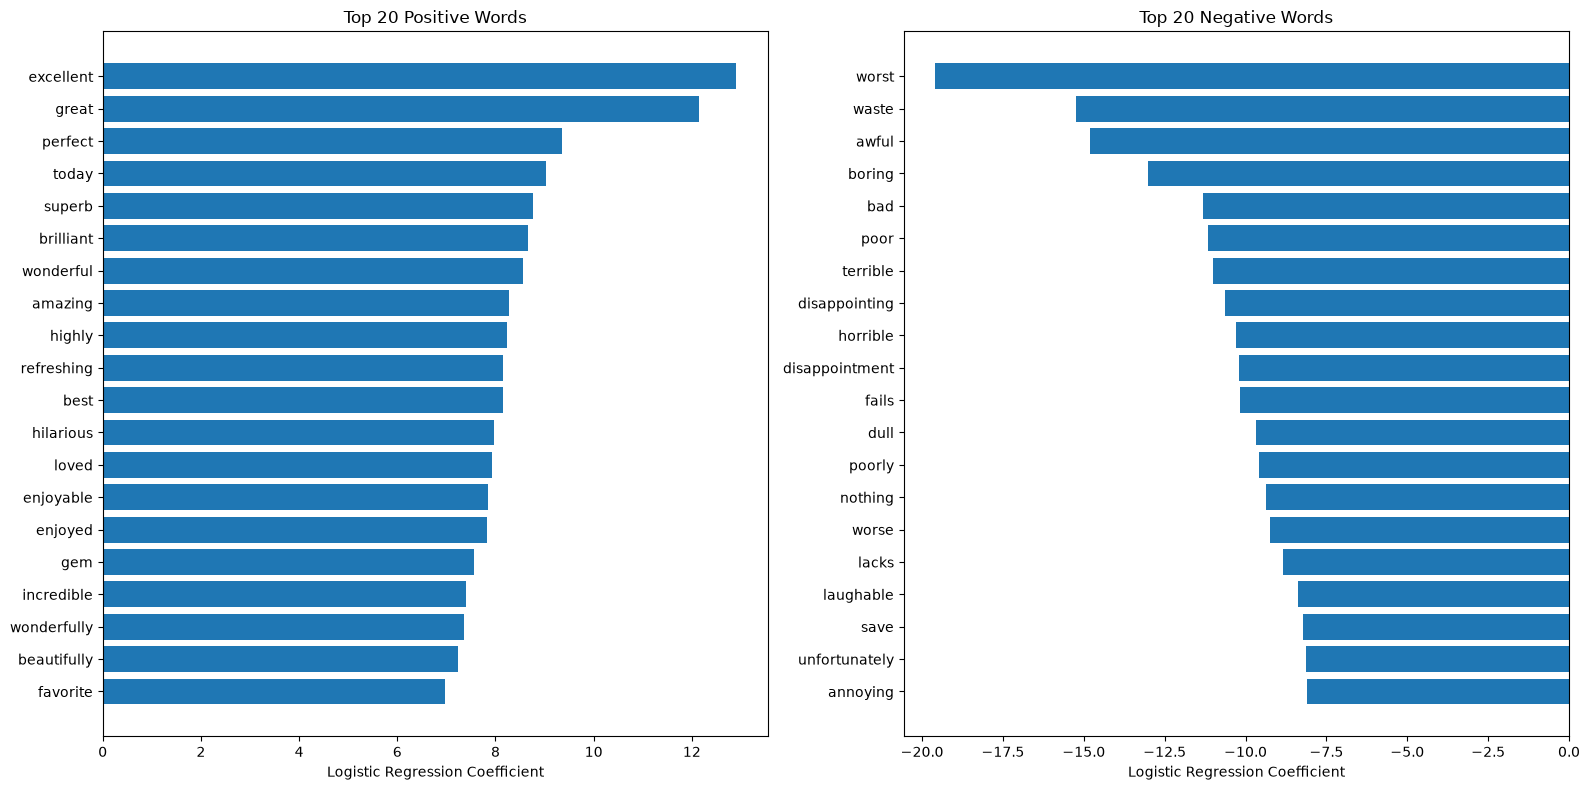

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
positive_plot = top_positive_words.sort_values(by="Coefficient")
negative_plot = top_negative_words.sort_values(by="Coefficient", ascending=False)
axes[0].barh(positive_plot["Word"], positive_plot["Coefficient"])
axes[0].set_title("Top 20 Positive Words")
axes[0].set_xlabel("Logistic Regression Coefficient")
axes[1].barh(negative_plot["Word"], negative_plot["Coefficient"])
axes[1].set_title("Top 20 Negative Words")
axes[1].set_xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

In [14]:
error_analysis_df = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual_sentiment": y_test.reset_index(drop=True),
    "predicted_sentiment": pd.Series(test_predictions)
})
misclassified_reviews = error_analysis_df[error_analysis_df["actual_sentiment"] != error_analysis_df["predicted_sentiment"]].copy()
print("Total test reviews:", len(error_analysis_df))
print("Misclassified reviews:", len(misclassified_reviews))
print("Test error rate:", round(len(misclassified_reviews) / len(error_analysis_df), 4))
print("\nFIRST 30 MISCLASSIFIED REVIEWS")
display( misclassified_reviews.head(30).reset_index(drop=True))

Total test reviews: 10000
Misclassified reviews: 1042
Test error rate: 0.1042

FIRST 30 MISCLASSIFIED REVIEWS


,review,actual_sentiment,predicted_sentiment
0,I sure would like to see a resurrection of a u...,positive,negative
1,Some films just simply should not be remade. T...,positive,negative
2,Honestly - this short film sucks. the dummy us...,negative,positive
3,The day has finally come for me to witness the...,negative,positive
4,Insignificant and low-brained (haha!) 80's hor...,negative,positive
5,"This series, made for Televisión Española (TVE...",negative,positive
6,"One of my sisters friends lent me this game, a...",negative,positive
7,This is an OK adaptation of the breath taking ...,positive,negative
8,A fey story of a Martian attempt to colonize E...,positive,negative
9,My ratings: Acting - 3/10 Suspense - 2/10 Char...,negative,positive


In [15]:
results_dir = PROJECT_ROOT / "results"
models_dir = results_dir / "models"
figures_dir = results_dir / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, models_dir / "final_sentiment_model.pkl")
final_metrics.to_csv(results_dir / "final_test_metrics.csv", index=False)
learning_curve_df.to_csv(results_dir / "learning_curve_results.csv", index=False)
word_importance.to_csv(results_dir / "word_importance.csv", index=False)
misclassified_reviews.to_csv(results_dir / "misclassified_reviews.csv", index=False)
error_analysis_df.to_csv(results_dir / "final_test_predictions.csv", index=False)
print("All final results saved successfully!")
print("Results directory:", results_dir)

All final results saved successfully!
Results directory: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment\results


In [16]:
print("=" * 65)
print("SENTIMENT ANALYSIS: FINAL PROJECT SUMMARY")
print("=" * 65)
print("\nFINAL MODEL")
print("Classifier: Logistic Regression")
print("Vectorizer:", type( final_model.named_steps["vectorizer"]).__name__)
print("\nDATASET")
print("Training reviews:", len(train_df))
print("Test reviews:", len(test_df))
print("\nFINAL TEST PERFORMANCE")
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1-score:  {final_f1:.4f}")
print(f"ROC-AUC:   {final_roc_auc:.4f}")
print("\nMISCLASSIFICATION ANALYSIS")
print("Misclassified reviews:", len(misclassified_reviews))
print("\nFINAL TRAINING TIME")
print(round(final_training_time, 2), "seconds")
print("\nNotebook 06 completed successfully!")

SENTIMENT ANALYSIS: FINAL PROJECT SUMMARY

FINAL MODEL
Classifier: Logistic Regression
Vectorizer: TfidfVectorizer

DATASET
Training reviews: 40000
Test reviews: 10000

FINAL TEST PERFORMANCE
Accuracy:  0.8958
Precision: 0.8879
Recall:    0.9060
F1-score:  0.8969
ROC-AUC:   0.9632

MISCLASSIFICATION ANALYSIS
Misclassified reviews: 1042

FINAL TRAINING TIME
12.17 seconds

Notebook 06 completed successfully!
